# 03 — Modélisation : trois modèles par objectif

Pour chaque objectif métier (BO), on construit **deux modèles développés from scratch** (tous les poids
partent du hasard et sont appris sur RoadAnomaly) et **un modèle pré-entraîné** (on réutilise un réseau
déjà entraîné sur ImageNet, 1,2 million de photos, puis on l'ajuste : transfert d'apprentissage).
Les neuf modèles sont entraînés sur les mêmes données, préparées au notebook 02. Ce notebook entraîne et
sauvegarde ; la comparaison et le choix du meilleur modèle se font au notebook 04.

| BO | Question | Modèle 1 · from scratch | Modèle 2 · from scratch | Modèle 3 · pré-entraîné |
|---|---|---|---|---|
| BO1 | Un obstacle est-il présent dans cette zone ? | CNN à 4 blocs | Autoencodeur débruiteur | ResNet-50 ImageNet |
| BO2 | Où est l'obstacle, pixel par pixel ? | U-Net | U-Net à encodeur ResNet-34 (poids aléatoires) | U-Net à encodeur ResNet-34 ImageNet |
| BO3 | Quelle part de la voie est occupée, où passer ? | CNN régresseur | Réseau dense (MLP) | ResNet-18 ImageNet |

### Étapes de ce notebook

1. Importer les bibliothèques et préparer les outils communs
2. BO1 — préparer les zones, puis définir, résumer et entraîner les 3 modèles
3. BO2 — préparer les images, puis définir, résumer et entraîner les 3 modèles
4. BO3 — préparer les cibles du couloir, puis définir, résumer et entraîner les 3 modèles
5. Récapituler l'entraînement

> Tous les chiffres, tableaux et figures de ce notebook sont produits par son exécution sur le jeu
> RoadAnomaly ; aucun résultat n'est écrit à la main.

## 0. Préparer l'environnement

On vérifie le GPU, on localise le dossier du projet (Colab ou local), on charge la configuration commune
(graine 42, résolution de travail 512 × 288) et on télécharge RoadAnomaly s'il est absent.

In [1]:
# Vérification du GPU (Colab : Exécution > Modifier le type d'exécution > GPU T4)
!nvidia-smi || echo "Pas de GPU visible : les entraînements seront très lents."

Thu Nov  5 15:11:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P8             15W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
USE_DRIVE = True   # False : travail dans /content (fichiers perdus à la fin de la session)
# Mode test rapide (activé par 00_main.ipynb) : 2 époques par modèle, sorties dans outputs_quick/.
# Sert uniquement à vérifier que la chaîne s'exécute ; ses chiffres ne doivent jamais être rapportés.
QUICK = os.environ.get('RA_QUICK') == '1'
EP = lambda n: 2 if QUICK else n

if os.environ.get('RA_PROJECT_DIR'):            # exécution pilotée par 00_main.ipynb (Drive déjà monté)
    PROJECT_DIR = os.environ['RA_PROJECT_DIR']
elif IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/RoadAnomaly_BO_Project'
elif IN_COLAB:
    PROJECT_DIR = '/content/RoadAnomaly_BO_Project'
else:
    PROJECT_DIR = os.path.abspath('..')        # exécution locale depuis notebooks/
DATA_DIR = os.path.join(PROJECT_DIR, 'data')   # contient (ou contiendra) RoadAnomaly/

# Si seul l'archive du projet a été déposée, on la décompresse
zip_path = PROJECT_DIR + '.zip'
if not os.path.isdir(os.path.join(PROJECT_DIR, 'src')) and os.path.isfile(zip_path):
    import zipfile
    zipfile.ZipFile(zip_path).extractall(os.path.dirname(PROJECT_DIR))
assert os.path.isdir(os.path.join(PROJECT_DIR, 'src')), \
    f"src/ introuvable dans {PROJECT_DIR} : copiez le dossier du projet à cet endroit."
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from src.config import ProjectPaths, TrainConfig, set_seed, environment_report, save_json, load_json
paths = ProjectPaths(PROJECT_DIR, DATA_DIR, outputs_name='outputs_quick' if QUICK else 'outputs')
cfg = TrainConfig()
set_seed(cfg.seed)
W, H = cfg.work_size
FIG, RES, PREDS, EXPORT = paths.sub('figures'), paths.sub('results'), paths.sub('preds'), paths.sub('webapp_models')
ENV = environment_report()
print(ENV)
if QUICK:
    print('*** MODE TEST RAPIDE : résultats NON valides, écrits dans', paths.outputs, '***')

{'python': '3.13.16', 'numpy': '2.4.6', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'sklearn': '1.6.1', 'PIL': '11.3.0', 'gradio': '6.31.0', 'cuda': '13.0', 'gpu': 'Tesla T4'}


In [3]:
from src.dataset import ensure_dataset, list_frames
ROOT = ensure_dataset(DATA_DIR)        # télécharge et décompresse le dataset si absent
print('Dataset :', ROOT)

Dataset : /content/RoadAnomaly_BO_Project/data/RoadAnomaly


In [4]:
import numpy as np
splits = load_json(os.path.join(paths.sub('splits'), 'splits.json'))    # produit par le notebook 02
z = np.load(os.path.join(paths.sub('processed'), f'arrays_{W}x{H}.npz'))
DATA = {s: (z[f'{s}_images'], z[f'{s}_masks'], list(z[f'{s}_names'])) for s in ['train', 'val', 'test']}
PREP = load_json(os.path.join(RES, '02_preprocessing.json'))
for s, (im, m, n) in DATA.items():
    print(f'{s:5s}', im.shape, m.shape)

train (40, 288, 512, 3) (40, 288, 512)
val   (10, 288, 512, 3) (10, 288, 512)
test  (10, 288, 512, 3) (10, 288, 512)


## 1. Importer les bibliothèques et préparer les outils communs

- `time_per_item` mesure le temps de calcul d'une prédiction (en millisecondes par zone ou par image).
- `record` enregistre le nombre de paramètres, la meilleure époque, la durée, l'historique, sauvegarde
  les poids et trace les courbes d'apprentissage.
- `model_summary` affiche l'architecture, comme `model.summary()` dans Keras.

In [5]:
import time, torch, torch.nn as nn, torch.nn.functional as F, pandas as pd, matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from src.config import get_device
from src.dataset import PatchDataset, SegmentationDataset, CorridorDataset, normalize
from src.models_catalog import BO_MODELS
from src.bo_models import model_summary, pretrained_params
from src.models import count_parameters
from src.train import (train_classifier, predict_proba, train_autoencoder, train_segmentation, predict_masks,
                       train_regressor, predict_regression, save_checkpoint)
from src.visualize import plot_learning_curves

device = get_device()
print('Calcul sur :', device)
CKPT = paths.sub('checkpoints')
SUMMARY = {}

@torch.no_grad()
def time_per_item(model, x, n=20):
    model.eval().to(device); x = x.to(device)
    for _ in range(3): model(x)
    if device.type == 'cuda': torch.cuda.synchronize()
    t = time.time()
    for _ in range(n): model(x)
    if device.type == 'cuda': torch.cuda.synchronize()
    return (time.time() - t) / n / len(x) * 1000      # ms par élément

def record(mid, model, hist, ms):
    SUMMARY[mid] = {'params_M': count_parameters(model) / 1e6, 'best_epoch': hist.get('best_epoch'),
                    'train_seconds': hist.get('seconds'), 'ms_per_item': ms,
                    'history': {k: v for k, v in hist.items() if isinstance(v, list)}}
    save_checkpoint(os.path.join(CKPT, f'{mid}.pth'), model,
                    {'model_id': mid, **{k: v for k, v in SUMMARY[mid].items() if k != 'history'}})
    keys = [k for k, v in hist.items() if isinstance(v, list)]
    plot_learning_curves(hist, keys, mid, path=os.path.join(FIG, f'03_curves_{mid}.png')); plt.show()
    print(f"{mid} : meilleure époque {hist.get('best_epoch')}, {SUMMARY[mid]['params_M']:.2f} M paramètres, "
          f"{ms:.2f} ms par élément")

Calcul sur : cuda


La brique `conv_block` sert à tous les modèles from scratch : deux convolutions 3 × 3, chacune suivie
d'une normalisation (BatchNorm) et d'une activation ReLU. Elle garde la taille de l'image et change le
nombre de canaux.

In [6]:
def conv_block(ci: int, co: int) -> nn.Sequential:
    """Brique de base des réseaux from scratch : deux convolutions 3×3 qui gardent la taille de l'image.
    Conv 3×3 (détecte des motifs locaux) -> BatchNorm (stabilise l'apprentissage) -> ReLU (non-linéarité),
    deux fois de suite."""
    return nn.Sequential(nn.Conv2d(ci, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                         nn.Conv2d(co, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True))

## 2. BO1 — Détecter la présence d'un obstacle dans une zone

### 2.1 Préparer les entrées

Les zones de 96 × 96 du notebook 02 : 1 527 en entraînement, dont environ 40 % avec obstacle. La perte de
classification est pondérée (les zones avec obstacle, moins nombreuses, comptent davantage). À
l'entraînement, chaque zone est retournée horizontalement une fois sur deux (miroir).

In [7]:
zp = np.load(os.path.join(paths.sub('processed'), 'patches_96.npz'))
P = {s: (zp[f'X_{s}'], zp[f'y_{s}']) for s in ['train', 'val', 'test']}
for s, (X, y) in P.items():
    print(f'{s:5s} {X.shape}  avec obstacle {int(y.sum())}  sans obstacle {int((y == 0).sum())}')
n_pos, n_neg = int(P['train'][1].sum()), int((P['train'][1] == 0).sum())
class_weights = torch.tensor([1.0, n_neg / max(n_pos, 1)], dtype=torch.float32)

def patch_loaders(size, bs, norm=True, subset=None):
    out = {}
    for s, (X, y) in P.items():
        if subset is not None and s in subset:
            keep = subset[s](y); X, y = X[keep], y[keep]
        out[s] = DataLoader(PatchDataset(X, y, size=size, augment=(s == 'train'), normalize_imagenet=norm),
                            batch_size=bs, shuffle=(s == 'train'), drop_last=(s == 'train'), num_workers=cfg.num_workers)
    return out

def save_bo1_scores(mid, val, test):   # scores de validation et de test, relus par le notebook 04
    np.savez_compressed(os.path.join(PREDS, f'{mid}.npz'), y_val=P['val'][1], s_val=val, y_test=P['test'][1], s_test=test)

train (1527, 96, 96, 3)  avec obstacle 624  sans obstacle 903
val   (413, 96, 96, 3)  avec obstacle 216  sans obstacle 197
test  (365, 96, 96, 3)  avec obstacle 150  sans obstacle 215


### 2.2 Modèle 1 — CNN à 4 blocs (from scratch)

Réseau convolutif classique conçu pour ce projet. Quatre blocs `conv_block` + MaxPool : à chaque bloc,
le nombre de filtres double (32, 64, 128, 256) et la taille de l'image est divisée par deux
(96 → 48 → 24 → 12 → 6). Une moyenne globale résume chaque carte en un nombre, puis une couche dense
donne deux scores : « sans obstacle » et « avec obstacle ».

| Couche | Sortie | Rôle |
|---|---|---|
| Entrée | 3 × 96 × 96 | zone RGB normalisée |
| Bloc 1 à 4 (conv 3×3 ×2, BatchNorm, ReLU, MaxPool) | 32×48×48 → 64×24×24 → 128×12×12 → 256×6×6 | motifs de plus en plus grands |
| Moyenne globale + Dropout 0,3 | 256 | résumé de la zone, régularisation |
| Dense | 2 | décision avec / sans obstacle |

**Définition du modèle** (code commenté couche par couche) :

In [8]:
class SmallCNN(nn.Module):
    """BO1 · modèle 1 · FROM SCRATCH — CNN à 4 blocs (classification avec / sans obstacle).

    Entrée : patch RGB normalisé (3, 96, 96). Sortie : 2 scores (logits) « sans obstacle », « avec obstacle ».
    Idée : chaque bloc double le nombre de filtres et divise la taille par 2 ; les premiers blocs voient des
    bords et des textures, les derniers des formes plus grandes (pelage, cône, roue).
    """

    def __init__(self, n_classes: int = 2, dropout: float = 0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Sequential(conv_block(3, 32), nn.MaxPool2d(2)),     # (3, 96, 96)   -> (32, 48, 48)
            nn.Sequential(conv_block(32, 64), nn.MaxPool2d(2)),    # (32, 48, 48)  -> (64, 24, 24)
            nn.Sequential(conv_block(64, 128), nn.MaxPool2d(2)),   # (64, 24, 24)  -> (128, 12, 12)
            nn.Sequential(conv_block(128, 256), nn.MaxPool2d(2)),  # (128, 12, 12) -> (256, 6, 6)
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),      # moyenne de chaque carte : (256, 6, 6) -> (256, 1, 1)
            nn.Flatten(),                 # -> vecteur de 256 valeurs
            nn.Dropout(dropout),          # éteint 30 % des valeurs à l'entraînement (contre le sur-apprentissage)
            nn.Linear(256, n_classes),    # couche dense de décision -> 2 scores
        )

    def forward(self, x):
        return self.head(self.features(x))

**Résumé de l'architecture** : forme de la sortie et nombre de paramètres de chaque couche.

In [9]:
set_seed(cfg.seed)
m = SmallCNN()
model_summary(m, (3, 96, 96), depth=2)

Paramètres : 1 173 730 au total | tous initialisés au hasard et appris from scratch


,couche,type,sortie,paramètres
0,features,Sequential,"(256, 6, 6)",1173216
1,features.0,Sequential,"(32, 48, 48)",10208
2,features.1,Sequential,"(64, 24, 24)",55552
3,features.2,Sequential,"(128, 12, 12)",221696
4,features.3,Sequential,"(256, 6, 6)",885760
5,head,Sequential,"(2,)",514
6,head.0,AdaptiveAvgPool2d,"(256, 1, 1)",0
7,head.1,Flatten,"(256,)",0
8,head.2,Dropout,"(256,)",0
9,head.3,Linear,"(2,)",514


**Entraînement.** 40 époques au plus, arrêt anticipé si le F1 de validation ne progresse plus pendant 10 époques ; optimiseur AdamW, taux d'apprentissage 1e-3 ; perte d'entropie croisée pondérée.

ép   1  loss 0.7203  val F1 0.105  AUROC 0.729  (4s)


ép   2  loss 0.5156  val F1 0.612  AUROC 0.700  (6s)


ép   3  loss 0.4659  val F1 0.705  AUROC 0.769  (7s)


ép   4  loss 0.4071  val F1 0.790  AUROC 0.838  (8s)


ép   5  loss 0.3889  val F1 0.799  AUROC 0.831  (10s)


ép   6  loss 0.3539  val F1 0.744  AUROC 0.813  (12s)


... (5 outputs left out)

ép  12  loss 0.2334  val F1 0.707  AUROC 0.809  (20s)


ép  13  loss 0.2120  val F1 0.777  AUROC 0.848  (21s)


ép  14  loss 0.2261  val F1 0.710  AUROC 0.750  (22s)


ép  15  loss 0.2148  val F1 0.754  AUROC 0.823  (24s)


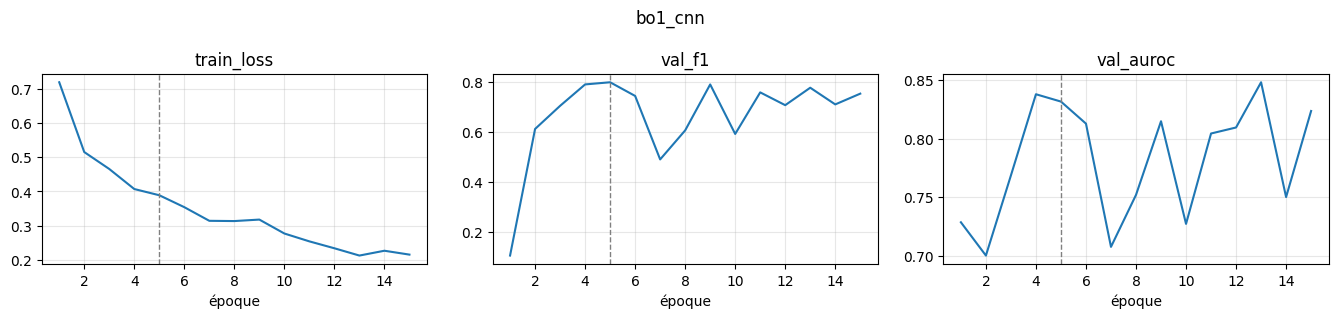

bo1_cnn : meilleure époque 5, 1.17 M paramètres, 0.30 ms par élément


In [10]:
L = patch_loaders(96, 64)
hist = train_classifier(m, L['train'], L['val'], device, epochs=EP(40), patience=10, lr_head=1e-3,
                        class_weights=class_weights, amp=cfg.amp)
sv, _ = predict_proba(m, L['val'], device); st, _ = predict_proba(m, L['test'], device)
save_bo1_scores('bo1_cnn', sv, st)
record('bo1_cnn', m, hist, time_per_item(m, next(iter(L['test']))[0]))

### 2.3 Modèle 2 — Autoencodeur convolutionnel débruiteur (from scratch, non supervisé)

Un autoencodeur apprend à **reconstruire** son entrée en la faisant passer par un goulot d'étranglement.
On ne lui montre **que des zones sans obstacle** : il apprend à quoi ressemble une route normale.
Version débruiteuse : on ajoute du bruit à l'entrée et on lui demande de rendre la zone propre, ce qui
l'oblige à apprendre la structure plutôt qu'à recopier. À l'usage, le score d'anomalie d'une zone est son
erreur de reconstruction : un obstacle, jamais vu, devrait être mal reconstruit.

| Partie | Couches | Sortie |
|---|---|---|
| Encodeur | 3 convolutions 4×4 de pas 2 (+ BatchNorm, LeakyReLU), conv 1×1 | 3×96×96 → 64×12×12 |
| Décodeur | conv 1×1, 3 convolutions transposées 4×4 de pas 2, sigmoïde | 64×12×12 → 3×96×96 |

**Définition du modèle** (code commenté couche par couche) :

In [11]:
class ConvAE(nn.Module):
    """BO1 · modèle 2 · FROM SCRATCH — autoencodeur convolutionnel débruiteur (non supervisé).

    Entraîné UNIQUEMENT sur des patches SANS obstacle, avec du bruit gaussien en entrée (σ = 0,1) et le
    patch propre comme cible. Il apprend donc à reconstruire « la route normale ». Score d'anomalie d'un
    patch = erreur de reconstruction : un obstacle, jamais vu, devrait être mal reconstruit.
    Entrée / sortie : patch RGB dans [0, 1], (3, 96, 96).
    """

    def __init__(self, latent_ch: int = 64):
        super().__init__()

        def down(ci, co):   # convolution 4×4 de pas 2 : divise la taille par 2
            return nn.Sequential(nn.Conv2d(ci, co, 4, 2, 1), nn.BatchNorm2d(co), nn.LeakyReLU(0.2, True))

        def up(ci, co):     # convolution transposée 4×4 de pas 2 : multiplie la taille par 2
            return nn.Sequential(nn.ConvTranspose2d(ci, co, 4, 2, 1), nn.BatchNorm2d(co), nn.ReLU(True))

        self.encoder = nn.Sequential(          # compresse l'image
            down(3, 32),                       # (3, 96, 96)   -> (32, 48, 48)
            down(32, 64),                      # (32, 48, 48)  -> (64, 24, 24)
            down(64, 128),                     # (64, 24, 24)  -> (128, 12, 12)
            nn.Conv2d(128, latent_ch, 1),      # goulot d'étranglement : (64, 12, 12), 9 216 valeurs au lieu de 27 648
        )
        self.decoder = nn.Sequential(          # reconstruit l'image à partir du code compressé
            nn.Conv2d(latent_ch, 128, 1),      # (64, 12, 12)  -> (128, 12, 12)
            up(128, 64),                       # -> (64, 24, 24)
            up(64, 32),                        # -> (32, 48, 48)
            nn.ConvTranspose2d(32, 3, 4, 2, 1),  # -> (3, 96, 96)
            nn.Sigmoid(),                      # valeurs ramenées dans [0, 1], comme l'image d'entrée
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

**Résumé de l'architecture** : forme de la sortie et nombre de paramètres de chaque couche.

In [12]:
set_seed(cfg.seed)
m = ConvAE()
model_summary(m, (3, 96, 96), depth=2)

Paramètres : 348 291 au total | tous initialisés au hasard et appris from scratch


,couche,type,sortie,paramètres
0,encoder,Sequential,"(64, 12, 12)",174304
1,encoder.0,Sequential,"(32, 48, 48)",1632
2,encoder.1,Sequential,"(64, 24, 24)",32960
3,encoder.2,Sequential,"(128, 12, 12)",131456
4,encoder.3,Conv2d,"(64, 12, 12)",8256
5,decoder,Sequential,"(3, 96, 96)",173987
6,decoder.0,Conv2d,"(128, 12, 12)",8320
7,decoder.1,Sequential,"(64, 24, 24)",131264
8,decoder.2,Sequential,"(32, 48, 48)",32864
9,decoder.3,ConvTranspose2d,"(3, 96, 96)",1539


**Entraînement.** Uniquement sur les zones sans obstacle ; bruit gaussien σ = 0,1 ; perte = erreur quadratique entre la reconstruction et la zone propre ; 60 époques au plus, patience 10.

ép   1  loss 0.03749  val 0.04433


ép   2  loss 0.01238  val 0.01668


ép   3  loss 0.00847  val 0.00977


ép   4  loss 0.00738  val 0.00880


ép   5  loss 0.00631  val 0.00977


ép   6  loss 0.00595  val 0.00771


... (49 outputs left out)

ép  56  loss 0.00222  val 0.00225


ép  57  loss 0.00263  val 0.00260


ép  58  loss 0.00237  val 0.00228


ép  59  loss 0.00235  val 0.00223


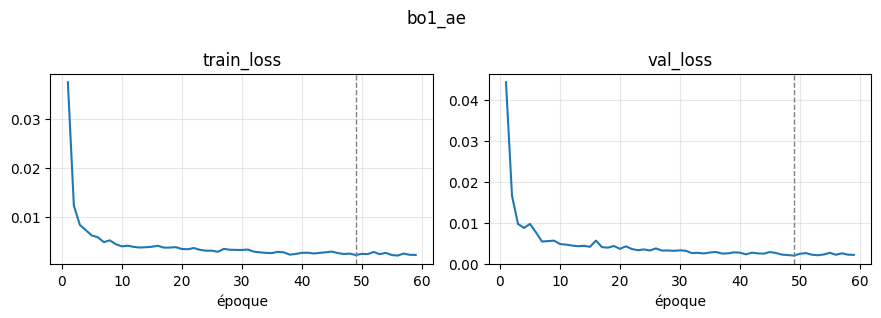

bo1_ae : meilleure époque 49, 0.35 M paramètres, 0.14 ms par élément


In [13]:
normal = {'train': lambda y: y == 0, 'val': lambda y: y == 0}
Ln = patch_loaders(96, 64, norm=False, subset=normal)          # zones normales uniquement

@torch.no_grad()
def recon_scores(model, loader):                               # erreur de reconstruction par zone
    model.eval(); out = []
    for x, _ in loader:
        x = x.to(device); out.append(((model(x) - x) ** 2).flatten(1).mean(1).cpu().numpy())
    return np.concatenate(out)

hist = train_autoencoder(m, Ln['train'], Ln['val'], device, epochs=EP(60), patience=10, noise_std=0.1)
La_eval = {s: DataLoader(PatchDataset(*P[s], size=96, normalize_imagenet=False), batch_size=128) for s in ['val', 'test']}
save_bo1_scores('bo1_ae', recon_scores(m, La_eval['val']), recon_scores(m, La_eval['test']))
record('bo1_ae', m, hist, time_per_item(m, next(iter(La_eval['test']))[0]))

### 2.4 Modèle 3 — ResNet-50 pré-entraîné sur ImageNet

**Transfert d'apprentissage.** Le ResNet-50 (He et al., 2016) a appris à reconnaître 1 000 catégories
d'objets sur ImageNet. Ses 49 premières couches savent déjà extraire des caractéristiques visuelles
générales (bords, textures, formes, parties d'animaux, de véhicules). On garde ces couches et on remplace
seulement la dernière (1 000 classes) par une couche à 2 sorties. Les blocs résiduels (raccourcis qui
additionnent l'entrée d'un bloc à sa sortie) permettent d'entraîner un réseau aussi profond.

| Partie | Origine | Sortie |
|---|---|---|
| Entrée | zone agrandie à 224 × 224, normalisée comme ImageNet | 3 × 224 × 224 |
| conv1 + 4 étages de blocs résiduels (3, 4, 6, 3 blocs) | **ImageNet**, ajustés | 2048 × 7 × 7 |
| Moyenne globale | — | 2048 |
| Dense 2048 → 2 | **nouvelle** | 2 |

**Définition du modèle** (code commenté couche par couche) :

In [14]:
class ResNet50Classifier(nn.Module):
    """BO1 · modèle 3 · PRÉ-ENTRAÎNÉ — ResNet-50 ImageNet (torchvision, poids IMAGENET1K_V2).

    Le ResNet-50 a appris sur 1,2 million de photos ImageNet à reconnaître 1 000 classes d'objets. On garde
    tout son extracteur de caractéristiques (50 couches, blocs résiduels) et on remplace seulement la
    dernière couche (1 000 classes) par une couche à 2 sorties. Entrée : patch agrandi à (3, 224, 224),
    normalisé comme ImageNet. Fine-tuning : taux d'apprentissage 1e-4 pour les couches pré-entraînées,
    1e-3 pour la nouvelle couche.
    """

    def __init__(self, n_classes: int = 2):
        super().__init__()
        import torchvision.models as tvm
        self.backbone = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V2)   # (3, 224, 224) -> (2048,)
        self.backbone.fc = nn.Linear(2048, n_classes)   # nouvelle tête : 2048 caractéristiques -> 2 scores

    def forward(self, x):
        return self.backbone(x)

**Résumé de l'architecture** : forme de la sortie et nombre de paramètres de chaque couche.

In [15]:
set_seed(cfg.seed)
m = ResNet50Classifier()
model_summary(m, (3, 224, 224), depth=2, pretrained=True)

Paramètres : 23 512 130 au total | dont 23 508 032 repris d'ImageNet  4 098 nouveaux


,couche,type,sortie,paramètres
0,backbone,ResNet,"(2,)",23512130
1,backbone.conv1,Conv2d,"(64, 112, 112)",9408
2,backbone.bn1,BatchNorm2d,"(64, 112, 112)",128
3,backbone.relu,ReLU,"(64, 112, 112)",0
4,backbone.maxpool,MaxPool2d,"(64, 56, 56)",0
5,backbone.layer1,Sequential,"(256, 56, 56)",215808
6,backbone.layer2,Sequential,"(512, 28, 28)",1219584
7,backbone.layer3,Sequential,"(1024, 14, 14)",7098368
8,backbone.layer4,Sequential,"(2048, 7, 7)",14964736
9,backbone.avgpool,AdaptiveAvgPool2d,"(2048, 1, 1)",0


**Entraînement.** Taux d'apprentissage différenciés : 1e-4 pour les couches ImageNet (on les ajuste doucement), 1e-3 pour la nouvelle couche ; 20 époques au plus, patience 6.

ép   1  loss 0.3041  val F1 0.862  AUROC 0.934  (16s)


ép   2  loss 0.0595  val F1 0.817  AUROC 0.927  (25s)


ép   3  loss 0.0174  val F1 0.827  AUROC 0.934  (35s)


ép   4  loss 0.0184  val F1 0.845  AUROC 0.931  (44s)


ép   5  loss 0.0069  val F1 0.845  AUROC 0.935  (53s)


ép   6  loss 0.0060  val F1 0.834  AUROC 0.925  (63s)


ép   7  loss 0.0150  val F1 0.813  AUROC 0.906  (72s)


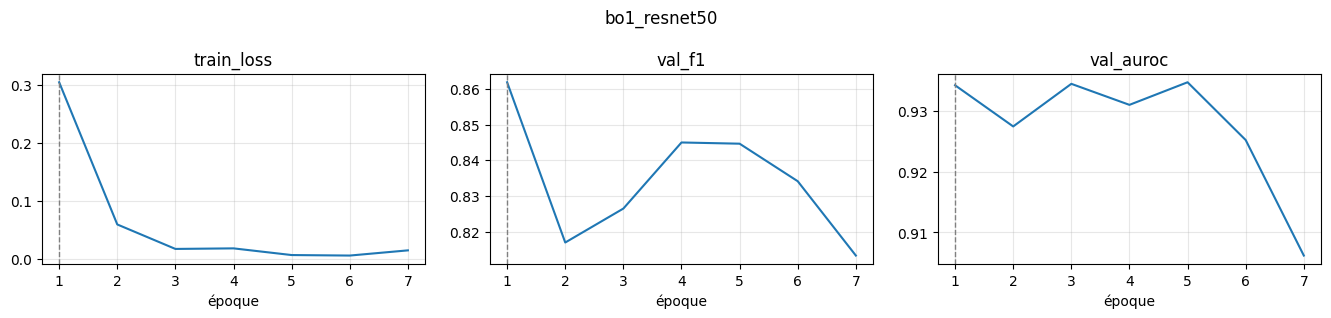

bo1_resnet50 : meilleure époque 1, 23.51 M paramètres, 3.63 ms par élément


In [16]:
L = patch_loaders(224, 32)
hist = train_classifier(m, L['train'], L['val'], device, epochs=EP(20), patience=6, lr_backbone=1e-4, lr_head=1e-3,
                        head_params=pretrained_params(m)[1], class_weights=class_weights, amp=cfg.amp)
sv, _ = predict_proba(m, L['val'], device); st, _ = predict_proba(m, L['test'], device)
save_bo1_scores('bo1_resnet50', sv, st)
record('bo1_resnet50', m, hist, time_per_item(m, next(iter(L['test']))[0]))
del m; torch.cuda.empty_cache()

## 3. BO2 — Localiser l'obstacle au pixel

### 3.1 Préparer les entrées

Images entières 512 × 288 normalisées ; chaque époque parcourt 4 fois les 40 images d'entraînement, avec
une augmentation différente à chaque fois. Perte commune aux trois modèles : entropie croisée binaire
pondérée (poids du notebook 02 sur les pixels d'obstacle) + perte Dice (qui mesure directement le
recouvrement). Le meilleur état de chaque modèle est celui du meilleur Dice de validation.

In [17]:
train_dl = DataLoader(SegmentationDataset(DATA['train'][0], DATA['train'][1], augment=True, repeats=4),
                      batch_size=cfg.batch_size, shuffle=True, drop_last=True, num_workers=cfg.num_workers, pin_memory=True)

def fit_bo2(mid, m, epochs, pretrained):
    set_seed(cfg.seed)
    head = pretrained_params(m)[1] if pretrained else None
    hist = train_segmentation(m, train_dl, DATA['val'][0], DATA['val'][1], device, epochs=EP(epochs),
                              patience=cfg.patience, lr_backbone=1e-4, lr_head=1e-3, head_params=head,
                              pos_weight=PREP['pos_weight'], amp=cfg.amp)
    pv, pt = predict_masks(m, DATA['val'][0], device), predict_masks(m, DATA['test'][0], device)
    np.savez_compressed(os.path.join(PREDS, f'{mid}.npz'), val=pv.astype(np.float16), test=pt.astype(np.float16))
    x = torch.from_numpy(np.stack([normalize(im) for im in DATA['test'][0][:2]]))
    record(mid, m, hist, time_per_item(m, x))

### 3.2 Modèle 1 — U-Net (from scratch)

Le U-Net (Ronneberger et al., 2015) est l'architecture de référence pour segmenter avec peu de données.
L'**encodeur** réduit l'image à chaque niveau pour comprendre ce qu'elle contient ; le **décodeur**
l'agrandit à nouveau pour dire où. Les **connexions de saut** recopient chaque niveau de l'encodeur dans
le décodeur, ce qui préserve les contours fins de l'obstacle.

| Niveau | Encodeur (sortie) | Décodeur (sortie) |
|---|---|---|
| 1 | 32 × 288 × 512 | 32 × 288 × 512 → couche finale 1 × 288 × 512 |
| 2 | 64 × 144 × 256 | 64 × 144 × 256 |
| 3 | 128 × 72 × 128 | 128 × 72 × 128 |
| 4 | 256 × 36 × 64 | 256 × 36 × 64 |
| fond du U | 512 × 18 × 32 (+ Dropout 0,2) | — |

**Définition du modèle** (code commenté couche par couche) :

In [18]:
class UNet(nn.Module):
    """BO2 · modèle 1 · FROM SCRATCH — U-Net (Ronneberger et al., 2015).

    Forme en « U » : un encodeur réduit l'image pour comprendre CE QU'IL Y A, un décodeur la ré-agrandit pour
    dire OÙ ; des connexions de saut recopient les détails fins de l'encodeur vers le décodeur.
    Entrée : (3, 288, 512) normalisée. Sortie : (1, 288, 512), un score « obstacle » par pixel (logit).
    """

    def __init__(self, out_ch: int = 1, base: int = 32, depth: int = 4, dropout: float = 0.2):
        super().__init__()
        chs = [base * 2 ** i for i in range(depth + 1)]                 # [32, 64, 128, 256, 512]
        # Encodeur : (32, 288, 512) -> (64, 144, 256) -> (128, 72, 128) -> (256, 36, 64) -> (512, 18, 32)
        self.enc = nn.ModuleList([conv_block(3 if i == 0 else chs[i - 1], chs[i]) for i in range(depth + 1)])
        self.pool = nn.MaxPool2d(2)                                      # divise la taille par 2 entre deux niveaux
        # Décodeur : convolution transposée (× 2), concaténation avec le niveau correspondant, conv_block
        self.up = nn.ModuleList([nn.ConvTranspose2d(chs[i + 1], chs[i], 2, stride=2) for i in reversed(range(depth))])
        self.dec = nn.ModuleList([conv_block(chs[i] * 2, chs[i]) for i in reversed(range(depth))])
        self.drop = nn.Dropout2d(dropout)                                # régularisation au fond du U
        self.head = nn.Conv2d(chs[0], out_ch, 1)                         # (32, 288, 512) -> (1, 288, 512)

    def forward(self, x):
        skips = []
        for i, block in enumerate(self.enc):          # descente : on garde chaque niveau pour les sauts
            x = block(x if i == 0 else self.pool(x))
            skips.append(x)
        x = self.drop(skips.pop())                     # fond du U : (512, 18, 32)
        for up, dec in zip(self.up, self.dec):         # remontée : agrandir, coller les détails, affiner
            x = dec(torch.cat([up(x), skips.pop()], dim=1))
        return self.head(x)

**Résumé de l'architecture** : forme de la sortie et nombre de paramètres de chaque couche.

In [19]:
set_seed(cfg.seed)
m = UNet()
model_summary(m, (3, 288, 512), depth=1)

Paramètres : 7 763 041 au total | tous initialisés au hasard et appris from scratch


,couche,type,sortie,paramètres
0,pool,MaxPool2d,"(32, 144, 256)",0
1,drop,Dropout2d,"(512, 18, 32)",0
2,head,Conv2d,"(1, 288, 512)",33


**Entraînement.** 100 époques au plus, patience 15, AdamW 1e-3 avec décroissance cosinus du taux d'apprentissage.

ép   5  loss 1.6573  val Dice 0.416  IoU 0.263  (32s)


ép  10  loss 1.5358  val Dice 0.544  IoU 0.373  (56s)


ép  15  loss 1.6883  val Dice 0.459  IoU 0.298  (80s)


ép  20  loss 1.5535  val Dice 0.477  IoU 0.313  (105s)


ép  25  loss 1.3547  val Dice 0.442  IoU 0.283  (129s)


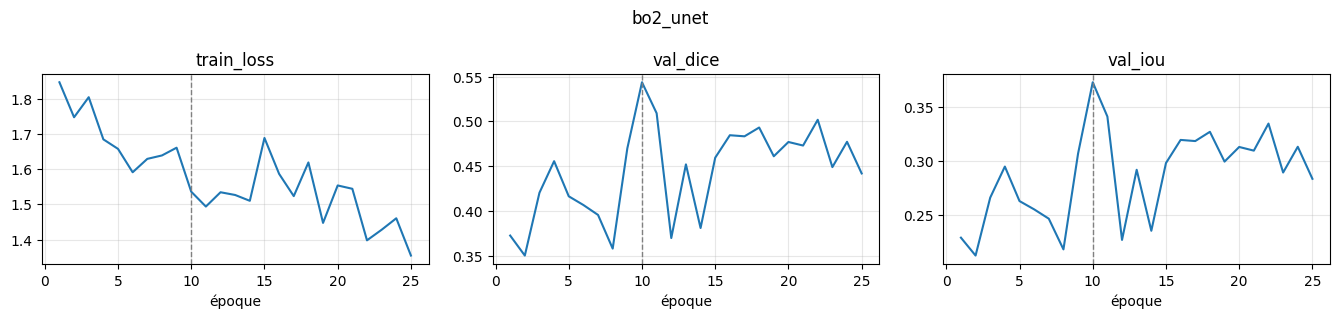

bo2_unet : meilleure époque 10, 7.76 M paramètres, 30.10 ms par élément


In [20]:
fit_bo2('bo2_unet', m, epochs=100, pretrained=False)
del m; torch.cuda.empty_cache()

### 3.3 Modèle 2 — U-Net à encodeur ResNet-34, poids aléatoires (from scratch)

Même principe en U, mais l'encodeur est un **ResNet-34** (34 couches, blocs résiduels) et le décodeur
agrandit par interpolation bilinéaire. Ici l'encodeur part de **poids aléatoires** : tout est appris sur
nos 40 images. Ce modèle sert de témoin pour le modèle 3, qui a exactement la même architecture.

| Partie | Couches | Sortie |
|---|---|---|
| Encodeur ResNet-34 | conv 7×7 de pas 2, MaxPool, 4 étages résiduels (3, 4, 6, 3 blocs) | 64×144×256 → 64×72×128 → 128×36×64 → 256×18×32 → 512×9×16 |
| Décodeur | 5 étapes `UpBlock` (× 2, saut, conv_block) | 256×18×32 → … → 32×288×512 |
| Sortie | conv 1×1 | 1 × 288 × 512 |

**Définition du modèle** (code commenté couche par couche) :

In [21]:
class UpBlock(nn.Module):
    """Étape du décodeur de ResNetUNet : agrandit × 2 (interpolation bilinéaire), concatène la carte de
    l'encodeur de même taille (connexion de saut), puis conv_block."""

    def __init__(self, cin: int, cskip: int, cout: int):
        super().__init__()
        self.conv = conv_block(cin + cskip, cout)

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        return self.conv(torch.cat([x, skip], 1) if skip is not None else x)


class ResNetUNet(nn.Module):
    """BO2 · modèles 2 et 3 — U-Net à encodeur ResNet-34.

    pretrained=False -> modèle 2, FROM SCRATCH : l'encodeur ResNet-34 part de poids aléatoires.
    pretrained=True  -> modèle 3, PRÉ-ENTRAÎNÉ : l'encodeur reprend les poids ImageNet ; le décodeur est neuf.
    Seule l'initialisation diffère entre les deux : l'écart de résultat mesure l'apport du pré-entraînement.
    Entrée : (3, 288, 512) normalisée. Sortie : (1, 288, 512), score « obstacle » par pixel.
    """

    def __init__(self, pretrained: bool = True, out_ch: int = 1):
        super().__init__()
        import torchvision
        r = torchvision.models.resnet34(weights=torchvision.models.ResNet34_Weights.IMAGENET1K_V1 if pretrained else None)
        self.encoder = nn.ModuleDict({                 # les couches du ResNet-34 (sans sa tête de classification)
            "stem": nn.Sequential(r.conv1, r.bn1, r.relu),   # conv 7×7 pas 2 : (3, 288, 512) -> (64, 144, 256)
            "pool": r.maxpool,                               # -> (64, 72, 128)
            "l1": r.layer1,                                  # 3 blocs résiduels -> (64, 72, 128)
            "l2": r.layer2,                                  # 4 blocs -> (128, 36, 64)
            "l3": r.layer3,                                  # 6 blocs -> (256, 18, 32)
            "l4": r.layer4,                                  # 3 blocs -> (512, 9, 16)
        })
        self.up4 = UpBlock(512, 256, 256)   # (512, 9, 16)   + saut l3 -> (256, 18, 32)
        self.up3 = UpBlock(256, 128, 128)   # + saut l2 -> (128, 36, 64)
        self.up2 = UpBlock(128, 64, 64)     # + saut l1 -> (64, 72, 128)
        self.up1 = UpBlock(64, 64, 64)      # + saut stem -> (64, 144, 256)
        self.up0 = UpBlock(64, 0, 32)       # sans saut -> (32, 288, 512)
        self.head = nn.Conv2d(32, out_ch, 1)  # -> (1, 288, 512)

    def forward(self, x):
        e = self.encoder
        s0 = e["stem"](x); s1 = e["l1"](e["pool"](s0)); s2 = e["l2"](s1); s3 = e["l3"](s2); s4 = e["l4"](s3)
        d = self.up1(self.up2(self.up3(self.up4(s4, s3), s2), s1), s0)
        return self.head(self.up0(d))

**Résumé de l'architecture** : forme de la sortie et nombre de paramètres de chaque couche.

In [22]:
set_seed(cfg.seed)
m = ResNetUNet(pretrained=False)
model_summary(m, (3, 288, 512), depth=1)

Paramètres : 24 521 697 au total | tous initialisés au hasard et appris from scratch


,couche,type,sortie,paramètres
0,up4,UpBlock,"(256, 18, 32)",2360320
1,up3,UpBlock,"(128, 36, 64)",590336
2,up2,UpBlock,"(64, 72, 128)",147712
3,up1,UpBlock,"(64, 144, 256)",110848
4,up0,UpBlock,"(32, 288, 512)",27776
5,head,Conv2d,"(1, 288, 512)",33


**Entraînement.** 80 époques au plus, patience 15, AdamW 1e-3 pour tout le réseau.

ép   5  loss 1.6800  val Dice 0.382  IoU 0.236  (26s)


ép  10  loss 1.6565  val Dice 0.451  IoU 0.291  (51s)


ép  15  loss 1.6622  val Dice 0.462  IoU 0.300  (76s)


ép  20  loss 1.5302  val Dice 0.491  IoU 0.325  (101s)


ép  25  loss 1.3974  val Dice 0.496  IoU 0.329  (125s)


ép  30  loss 1.3772  val Dice 0.549  IoU 0.378  (150s)


... (3 outputs left out)

ép  50  loss 1.1586  val Dice 0.596  IoU 0.425  (249s)


ép  55  loss 1.1097  val Dice 0.602  IoU 0.430  (273s)


ép  60  loss 0.9798  val Dice 0.603  IoU 0.432  (297s)


ép  65  loss 1.0536  val Dice 0.606  IoU 0.435  (322s)


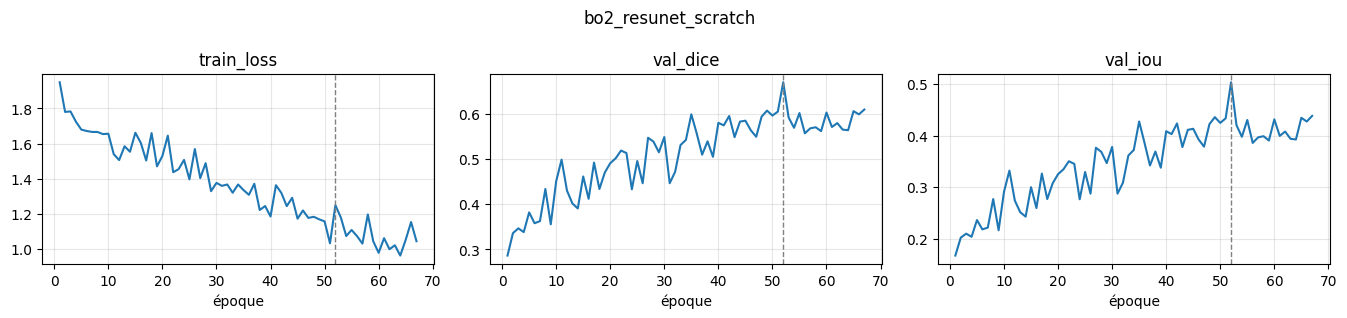

bo2_resunet_scratch : meilleure époque 52, 24.52 M paramètres, 26.60 ms par élément


In [23]:
fit_bo2('bo2_resunet_scratch', m, epochs=80, pretrained=False)
del m; torch.cuda.empty_cache()

### 3.4 Modèle 3 — U-Net à encodeur ResNet-34 pré-entraîné sur ImageNet

Exactement le réseau du modèle 2, mais l'encodeur reprend les **poids ImageNet** ; seul le décodeur part
de zéro. Comparer les modèles 2 et 3 isole l'effet du pré-entraînement : même architecture, mêmes
données, même graine, seule l'initialisation change.

**Définition du modèle** (code commenté couche par couche) :

**Résumé de l'architecture** : forme de la sortie et nombre de paramètres de chaque couche.

In [24]:
set_seed(cfg.seed)
m = ResNetUNet(pretrained=True)
model_summary(m, (3, 288, 512), depth=1, pretrained=True)

Paramètres : 24 521 697 au total | dont 21 284 672 repris d'ImageNet  3 237 025 nouveaux


,couche,type,sortie,paramètres
0,up4,UpBlock,"(256, 18, 32)",2360320
1,up3,UpBlock,"(128, 36, 64)",590336
2,up2,UpBlock,"(64, 72, 128)",147712
3,up1,UpBlock,"(64, 144, 256)",110848
4,up0,UpBlock,"(32, 288, 512)",27776
5,head,Conv2d,"(1, 288, 512)",33


**Entraînement.** 60 époques au plus, patience 15 ; taux 1e-4 pour l'encodeur ImageNet, 1e-3 pour le décodeur neuf.

ép   5  loss 0.7718  val Dice 0.811  IoU 0.682  (25s)


ép  10  loss 0.5746  val Dice 0.807  IoU 0.676  (49s)


ép  15  loss 0.4239  val Dice 0.780  IoU 0.640  (74s)


ép  20  loss 0.3103  val Dice 0.787  IoU 0.649  (99s)


ép  25  loss 0.1855  val Dice 0.839  IoU 0.723  (123s)


ép  30  loss 0.2151  val Dice 0.784  IoU 0.645  (148s)


ép  35  loss 0.1850  val Dice 0.783  IoU 0.643  (173s)


ép  40  loss 0.1477  val Dice 0.814  IoU 0.687  (198s)


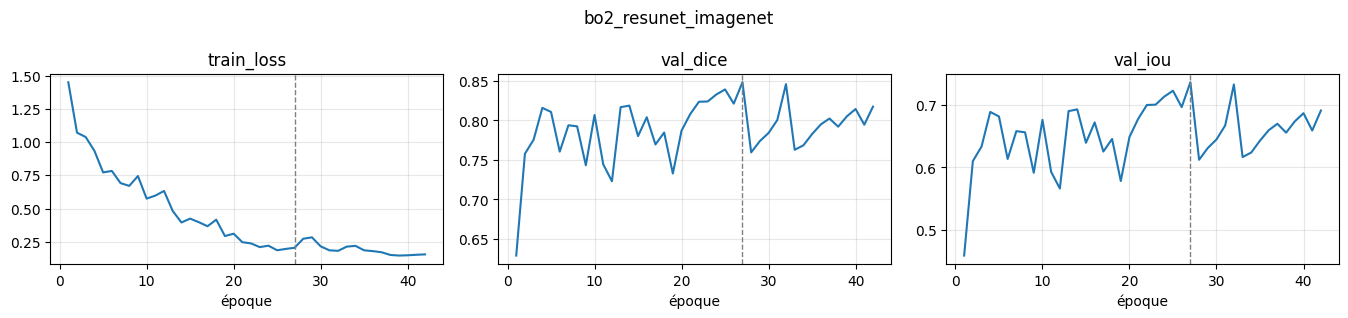

bo2_resunet_imagenet : meilleure époque 27, 24.52 M paramètres, 26.53 ms par élément


In [25]:
fit_bo2('bo2_resunet_imagenet', m, epochs=60, pretrained=True)
del m; torch.cuda.empty_cache()

## 4. BO3 — Occupation et espace libre du couloir de conduite

### 4.1 Préparer les entrées et les cibles

Le jeu de données n'annote pas la chaussée. On définit donc un **couloir de conduite fixe** devant le
véhicule : un trapèze du bas de l'image (de 10 % à 90 % de la largeur) jusqu'à 55 % de sa hauteur
(de 40 % à 60 %). Pour chaque image, trois cibles sont calculées à partir du vrai masque :

- **occupation** : part du couloir couverte par l'obstacle ;
- **libre à gauche / à droite** : espace libre de chaque côté de l'obstacle, en part de la largeur du
  couloir, mesuré au contact de l'obstacle avec la chaussée (25 % les plus bas de ses lignes).

Entrée des modèles : image 256 × 144. Les cibles sont recalculées après chaque augmentation (un miroir
échange la gauche et la droite). Perte Smooth L1 ; meilleur état = plus petite erreur moyenne de validation.

In [26]:
BO3_SIZE = (256, 144)
ds = {s: CorridorDataset(DATA[s][0], DATA[s][1], size_wh=BO3_SIZE, augment=(s == 'train'), repeats=8 if s == 'train' else 1)
      for s in ['train', 'val', 'test']}
loaders = {s: DataLoader(d, batch_size=8, shuffle=(s == 'train'), drop_last=(s == 'train'), num_workers=cfg.num_workers)
           for s, d in ds.items()}
x0, t0 = ds['val'][0]
print('entrée', tuple(x0.shape), '| cibles [occupation, libre gauche, libre droite] =', np.round(t0.numpy(), 3))

def fit_bo3(mid, m, pretrained):
    set_seed(cfg.seed)
    head = pretrained_params(m)[1] if pretrained else None
    hist = train_regressor(m, loaders['train'], loaders['val'], device, epochs=EP(80), patience=15,
                           lr_backbone=1e-4, lr_head=1e-3, head_params=head)
    pv, tv = predict_regression(m, loaders['val'], device)
    pt, tt = predict_regression(m, loaders['test'], device)
    np.savez_compressed(os.path.join(PREDS, f'{mid}.npz'), p_val=pv, t_val=tv, p_test=pt, t_test=tt)
    record(mid, m, hist, time_per_item(m, next(iter(loaders['test']))[0]))

entrée (3, 144, 256) | cibles [occupation, libre gauche, libre droite] = [0.75  0.344 0.   ]


### 4.2 Modèle 1 — CNN régresseur (from scratch)

Même famille que le CNN de BO1, avec un bloc de plus car l'image est plus grande, et une sortie de
**régression** : trois nombres passés dans une sigmoïde pour rester entre 0 et 1 (ce sont des proportions).

| Couche | Sortie |
|---|---|
| Entrée | 3 × 144 × 256 |
| 5 blocs `conv_block` + MaxPool | 32×72×128 → 64×36×64 → 128×18×32 → 128×9×16 → 256×4×8 |
| Moyenne globale + Dropout 0,3 | 256 |
| Dense + sigmoïde | 3 : occupation, libre gauche, libre droite |

**Définition du modèle** (code commenté couche par couche) :

In [27]:
class CorridorCNN(nn.Module):
    """BO3 · modèle 1 · FROM SCRATCH — CNN régresseur.

    Entrée : image entière (3, 144, 256) normalisée. Sortie : 3 nombres entre 0 et 1 :
    [occupation du couloir, espace libre à gauche, espace libre à droite].
    """

    def __init__(self, n_out: int = 3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Sequential(conv_block(3, 32), nn.MaxPool2d(2)),      # (3, 144, 256)  -> (32, 72, 128)
            nn.Sequential(conv_block(32, 64), nn.MaxPool2d(2)),     # -> (64, 36, 64)
            nn.Sequential(conv_block(64, 128), nn.MaxPool2d(2)),    # -> (128, 18, 32)
            nn.Sequential(conv_block(128, 128), nn.MaxPool2d(2)),   # -> (128, 9, 16)
            nn.Sequential(conv_block(128, 256), nn.MaxPool2d(2)),   # -> (256, 4, 8)
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),   # -> 256 valeurs
                                  nn.Dropout(0.3), nn.Linear(256, n_out))   # -> 3 valeurs

    def forward(self, x):
        return torch.sigmoid(self.head(self.features(x)))

**Résumé de l'architecture** : forme de la sortie et nombre de paramètres de chaque couche.

In [28]:
set_seed(cfg.seed)
m = CorridorCNN()
model_summary(m, (3, 144, 256), depth=2)

Paramètres : 1 469 411 au total | tous initialisés au hasard et appris from scratch


,couche,type,sortie,paramètres
0,features,Sequential,"(256, 4, 8)",1468640
1,features.0,Sequential,"(32, 72, 128)",10208
2,features.1,Sequential,"(64, 36, 64)",55552
3,features.2,Sequential,"(128, 18, 32)",221696
4,features.3,Sequential,"(128, 9, 16)",295424
5,features.4,Sequential,"(256, 4, 8)",885760
6,head,Sequential,"(3,)",771
7,head.0,AdaptiveAvgPool2d,"(256, 1, 1)",0
8,head.1,Flatten,"(256,)",0
9,head.2,Dropout,"(256,)",0


**Entraînement.** 80 époques au plus, patience 15, AdamW 1e-3.

ép   5  loss 0.1967  val MAE 0.2212  (26s)


ép  10  loss 0.1807  val MAE 0.2229  (48s)


ép  15  loss 0.1842  val MAE 0.1949  (73s)


ép  20  loss 0.1687  val MAE 0.2296  (97s)


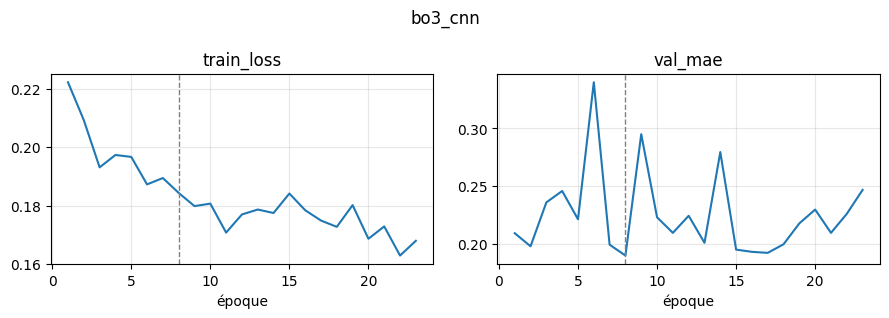

bo3_cnn : meilleure époque 8, 1.47 M paramètres, 1.80 ms par élément


In [29]:
fit_bo3('bo3_cnn', m, pretrained=False)
del m; torch.cuda.empty_cache()

### 4.3 Modèle 2 — Réseau dense MLP (from scratch)

Réseau de neurones « classique » du cours (ANN) : aucune convolution. L'image est réduite à 64 × 36, mise
à plat en un vecteur de 6 912 valeurs, puis traversée par deux couches cachées denses (512 puis 128
neurones, BatchNorm, ReLU, Dropout 0,3). Il ne connaît pas la notion de voisinage entre pixels : il sert de
point de comparaison pour mesurer ce qu'apportent les convolutions.

| Couche | Sortie |
|---|---|
| Réduction de l'image + mise à plat | 6 912 |
| Dense 1 (+ BatchNorm, ReLU, Dropout) | 512 |
| Dense 2 (+ BatchNorm, ReLU, Dropout) | 128 |
| Dense + sigmoïde | 3 |

**Définition du modèle** (code commenté couche par couche) :

In [30]:
class CorridorMLP(nn.Module):
    """BO3 · modèle 2 · FROM SCRATCH — réseau de neurones dense (MLP, « ANN » du cours).

    Aucune convolution : l'image réduite à 64 × 36 est mise à plat en un vecteur de 6 912 valeurs, puis
    traversée par deux couches denses. Sert de point de comparaison : sans structure spatiale, le réseau a
    beaucoup de mal à localiser l'obstacle.
    """

    def __init__(self, size_wh=(64, 36), n_out: int = 3, hidden=(512, 128), dropout: float = 0.3):
        super().__init__()
        self.size = (size_wh[1], size_wh[0])
        self.net = nn.Sequential(
            nn.Flatten(),                                     # (3, 36, 64) -> 6 912 valeurs
            nn.Linear(3 * size_wh[0] * size_wh[1], hidden[0]), nn.BatchNorm1d(hidden[0]),
            nn.ReLU(inplace=True), nn.Dropout(dropout),       # couche cachée 1 : 512 neurones
            nn.Linear(hidden[0], hidden[1]), nn.BatchNorm1d(hidden[1]),
            nn.ReLU(inplace=True), nn.Dropout(dropout),       # couche cachée 2 : 128 neurones
            nn.Linear(hidden[1], n_out),                      # sortie : 3 valeurs
        )

    def forward(self, x):
        x = F.interpolate(x, size=self.size, mode="bilinear", align_corners=False)   # (3, 144, 256) -> (3, 36, 64)
        return torch.sigmoid(self.net(x))

**Résumé de l'architecture** : forme de la sortie et nombre de paramètres de chaque couche.

In [31]:
set_seed(cfg.seed)
m = CorridorMLP()
model_summary(m, (3, 144, 256), depth=1)

Paramètres : 3 606 787 au total | tous initialisés au hasard et appris from scratch


,couche,type,sortie,paramètres
0,net,Sequential,"(3,)",3606787


**Entraînement.** 80 époques au plus, patience 15, AdamW 1e-3.

ép   5  loss 0.1496  val MAE 0.2345  (22s)


ép  10  loss 0.1304  val MAE 0.2632  (43s)


ép  15  loss 0.1137  val MAE 0.2508  (66s)


ép  20  loss 0.1122  val MAE 0.2610  (87s)


ép  25  loss 0.1084  val MAE 0.2474  (109s)


ép  30  loss 0.1010  val MAE 0.2486  (131s)


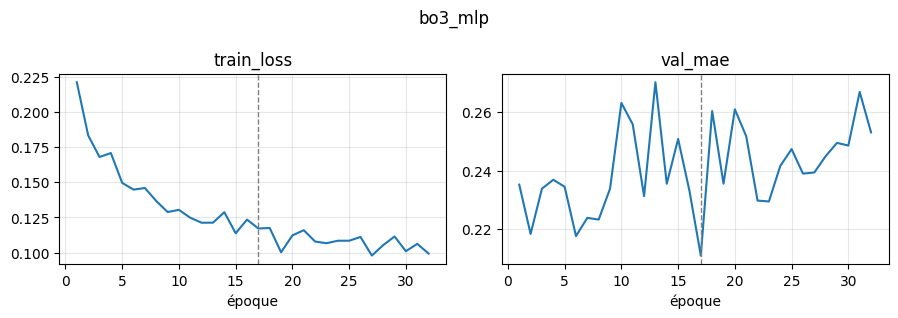

bo3_mlp : meilleure époque 17, 3.61 M paramètres, 0.05 ms par élément


In [32]:
fit_bo3('bo3_mlp', m, pretrained=False)
del m; torch.cuda.empty_cache()

### 4.4 Modèle 3 — ResNet-18 pré-entraîné sur ImageNet

Transfert d'apprentissage comme pour BO1, avec un réseau plus léger : le **ResNet-18** (18 couches, 4
étages de 2 blocs résiduels). Ses couches ImageNet sont conservées et ajustées ; la dernière couche est
remplacée par Dropout 0,3 + une couche dense 512 → 3, suivie d'une sigmoïde.

| Partie | Origine | Sortie |
|---|---|---|
| conv1 + 4 étages résiduels | **ImageNet**, ajustés | 512 × 5 × 8 |
| Moyenne globale | — | 512 |
| Dropout + Dense 512 → 3 + sigmoïde | **nouvelle** | 3 |

**Définition du modèle** (code commenté couche par couche) :

In [33]:
class PretrainedRegressor(nn.Module):
    """BO3 · modèle 3 · PRÉ-ENTRAÎNÉ — ResNet-18 ImageNet, tête de régression à 3 sorties.

    Extracteur ResNet-18 (18 couches, poids ImageNet) conservé ; sa couche finale de 1 000 classes est
    remplacée par Dropout + couche dense 512 -> 3. Entrée (3, 144, 256) normalisée ; sortie : les trois
    proportions du couloir. Fine-tuning à taux différenciés (1e-4 / 1e-3).
    """

    def __init__(self, n_out: int = 3):
        super().__init__()
        import torchvision.models as tvm
        self.backbone = tvm.resnet18(weights=tvm.ResNet18_Weights.IMAGENET1K_V1)   # -> 512 caractéristiques
        self.backbone.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, n_out))   # nouvelle tête

    def forward(self, x):
        return torch.sigmoid(self.backbone(x))

**Résumé de l'architecture** : forme de la sortie et nombre de paramètres de chaque couche.

In [34]:
set_seed(cfg.seed)
m = PretrainedRegressor()
model_summary(m, (3, 144, 256), depth=2, pretrained=True)

Paramètres : 11 178 051 au total | dont 11 176 512 repris d'ImageNet  1 539 nouveaux


,couche,type,sortie,paramètres
0,backbone,ResNet,"(3,)",11178051
1,backbone.conv1,Conv2d,"(64, 72, 128)",9408
2,backbone.bn1,BatchNorm2d,"(64, 72, 128)",128
3,backbone.relu,ReLU,"(64, 72, 128)",0
4,backbone.maxpool,MaxPool2d,"(64, 36, 64)",0
5,backbone.layer1,Sequential,"(64, 36, 64)",147968
6,backbone.layer2,Sequential,"(128, 18, 32)",525568
7,backbone.layer3,Sequential,"(256, 9, 16)",2099712
8,backbone.layer4,Sequential,"(512, 5, 8)",8393728
9,backbone.avgpool,AdaptiveAvgPool2d,"(512, 1, 1)",0


**Entraînement.** 80 époques au plus, patience 15 ; taux 1e-4 pour les couches ImageNet, 1e-3 pour la nouvelle tête.

ép   5  loss 0.0965  val MAE 0.2127  (25s)


ép  10  loss 0.0937  val MAE 0.1401  (50s)


ép  15  loss 0.0719  val MAE 0.1480  (73s)


ép  20  loss 0.0664  val MAE 0.1322  (97s)


ép  25  loss 0.0599  val MAE 0.1341  (122s)


ép  30  loss 0.0586  val MAE 0.1257  (147s)


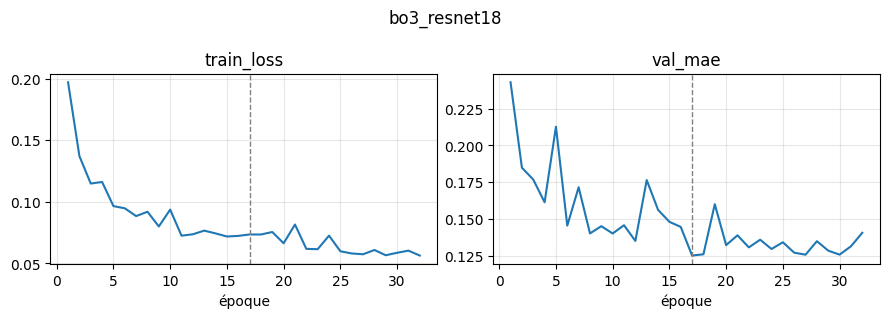

bo3_resnet18 : meilleure époque 17, 11.18 M paramètres, 1.51 ms par élément


In [35]:
fit_bo3('bo3_resnet18', m, pretrained=True)
del m; torch.cuda.empty_cache()

## 5. Récapituler l'entraînement

In [36]:
rows = [{'BO': bo, 'modèle': f"{s['name']} ({s['init']})", 'id': s['id'],
         **{k: SUMMARY.get(s['id'], {}).get(k) for k in ['params_M', 'best_epoch', 'train_seconds', 'ms_per_item']}}
        for bo, lst in BO_MODELS.items() for s in lst]
display(pd.DataFrame(rows).round(2))
save_json({'notebook': '03', 'env': ENV, 'config': cfg.to_dict(), 'bo3_size': BO3_SIZE, 'models': SUMMARY},
          os.path.join(RES, '03_training.json'))

,BO,modèle,id,params_M,best_epoch,train_seconds,ms_per_item
0,BO1,CNN à 4 blocs (from scratch),bo1_cnn,1.17,5,24.11,0.30
1,BO1,Autoencodeur convolutionnel débruiteur (from s...,bo1_ae,0.35,49,NaN,0.14
2,BO1,ResNet-50 (pré-entraîné ImageNet),bo1_resnet50,23.51,1,72.25,3.63
3,BO2,U-Net (from scratch),bo2_unet,7.76,10,129.08,30.10
4,BO2,U-Net à encodeur ResNet-34 (from scratch),bo2_resunet_scratch,24.52,52,332.12,26.60
5,BO2,U-Net à encodeur ResNet-34 (pré-entraîné Image...,bo2_resunet_imagenet,24.52,27,207.25,26.53
6,BO3,CNN régresseur (from scratch),bo3_cnn,1.47,8,111.32,1.80
7,BO3,Réseau dense (MLP) (from scratch),bo3_mlp,3.61,17,140.01,0.05
8,BO3,ResNet-18 (pré-entraîné ImageNet),bo3_resnet18,11.18,17,155.20,1.51


## Observations (rédigées à partir des sorties ci-dessus, exécution du 05/11/2026)

- **Convergence.** Le ResNet-50 (BO1) atteint son meilleur F1 de validation dès la 1re époque : les caractéristiques ImageNet suffisent presque telles quelles. Pour BO2, le U-Net ResNet-34 pré-entraîné atteint son meilleur Dice à l'époque 27, contre 52 pour le même réseau parti de poids aléatoires ; le U-Net simple s'arrête tôt (époque 10). Pour BO3, le ResNet-18 converge à l'époque 17.
- **Durées sur GPU T4** : BO1 24 s (CNN) et 72 s (ResNet-50) ; BO2 129 s (U-Net), 332 s (ResNet-34 aléatoire), 207 s (ResNet-34 ImageNet) ; BO3 111 s (CNN), 140 s (MLP), 155 s (ResNet-18). Notebook complet : 21 minutes.
- **Taille et vitesse** : de 0,35 M (autoencodeur) à 24,5 M paramètres (U-Net ResNet-34) ; 25 à 30 ms par image pour les modèles BO2, 0,3 ms (CNN) à 3,6 ms (ResNet-50) par zone pour BO1.